# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


<div class="alert alert-block alert-info">
¡Hola Jo! ¿Cómo va?<br><br>
Un gusto conocerte, seré tu revisor en este proyecto. Te comparto la modalidad de revisión que vamos a usar:<br><br>
Cuando encuentre un error por primera vez, simplemente lo señalaré y dejaré que lo detectes y corrijas por tu cuenta. Además, a lo largo del proyecto iré haciendo algunas observaciones para mejorar tu código, así como comentarios sobre tus conclusiones.<br><br>
Si en algún momento no logras resolver la tarea, en la siguiente iteración te daré una pista más precisa, junto con algunos ejemplos prácticos. También estoy abierto a responder cualquier duda que tengas.<br><br>
Encontrarás mis comentarios a continuación: <b>por favor, no los muevas, modifiques ni elimines</b>.<br><br>
Puedes encontrar mis comentarios en cuadros verdes, amarillos o rojos como estos:
</div>

<div class="alert alert-block alert-success">
<b>Comentario del revisor.</b><br>Éxito. Todo se ha hecho de forma correcta.
</div>

<div class="alert alert-block alert-warning">
<b>Comentario del revisor.</b><br>Observación. Algunas recomendaciones o mejoras menores.
</div>

<div class="alert alert-block alert-danger">
<b>Comentario del revisor.</b><br>Necesita arreglos. Este apartado requiere algunas correcciones. El trabajo no puede ser aceptado con comentarios rojos.
</div>

<div class="alert alert-block alert-info">
Además verás cuadros azules 💡 con <b>tips de eficiencia</b> opcionales.<br><br>Puedes responder utilizando este formato:<br><br><b>Respuesta del estudiante.</b>
</div>

<div class="alert alert-block alert-success">
<b>Review General. (Iteración 1)</b> <a class="tocSkip"></a><br><br>
Quería tomarme este momento al inicio de tu proyecto para comentarte mis apreciaciones generales sobre esta entrega.<br><br>
Antes que nada, ¡felicitaciones por el esfuerzo! Completaste todo el flujo del proyecto, con código ordenado y respuestas en cada paso. Identificaste ambos sentinels, revisaste los años con <code>.dt.year.value_counts()</code> y tu análisis MAR está muy bien razonado. Recuerda que equivocarse es parte del aprendizaje: cada iteración te acerca a pensar como un gran analista de datos.<br><br>
<b>Resumen de tu proyecto por partes</b>
<ul>
<li><b>Parte 1. Carga y exploración ✅</b> — Rutas, variables y exploración con <code>head()</code>, <code>shape</code> e <code>info()</code> completas.</li>
<li><b>Parte 2. Calidad de datos ✅</b> — Nulos con cantidad y proporción, ambos sentinels (<code>-999</code> y <code>"?"</code>), <code>errors='coerce'</code> y conteo por año con los 40 registros de 2026.</li>
<li><b>Parte 3. Limpieza 🟡</b> — Reemplazos de <code>age</code> y <code>city</code> correctos. Al marcar las fechas, <code>reg_date</code> quedó convertida en el año (un número) y se perdió la fecha completa.</li>
<li><b>Parte 4. Uso por usuario ❌</b> — Agregación y <code>merge</code> con <code>how='left'</code> correctos, pero a partir del paso 4.2 el análisis se hace solo con los <b>1330 clientes registrados en 2024</b>, en lugar de los 4000.</li>
<li><b>Parte 5. Distribuciones y outliers ✅</b> — Histogramas por plan, boxplots en ciclo y límites IQR (aunque calculados sobre el subconjunto).</li>
<li><b>Parte 6. Segmentación ✅</b> — <code>np.where</code> anidados, como sugiere la rúbrica, y countplots bien rotulados.</li>
<li><b>Parte 7. Insight ejecutivo 🟡</b> — Respondes las preguntas, pero faltan cifras, los sentinels y las fechas de 2026 en los problemas, y más recomendaciones.</li>
<li><b>Parte 8. Publicación 🟡</b> — El link está en una celda de código.</li>
</ul>
<b>Estado de la entrega:</b> el proyecto <b>aún no puede ser aceptado</b> por un único comentario rojo: el <b>filtro por año de registro</b> del paso 4.2, que deja fuera a dos tercios de los clientes y cambia todos los resultados posteriores. Es un ajuste de pocas líneas: tu código para los gráficos y la segmentación ya está bien hecho. Los comentarios amarillos son recomendaciones para fortalecer tu trabajo.<br><br>
Espero con ansias tu próxima iteración. ¡Bien hecho!<br><br>Saludos.
</div>

--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [1]:
# importar librerías
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Importaste las librerías en una sola celda al inicio. ¡Buena práctica!
</div>

<div class="alert alert-block alert-info">
<b>💡 Comentario del revisor. (Iteración 1) — Tip de eficiencia</b> <a class="tocSkip"></a><br>
Agrega aquí también <code>import numpy as np</code>, que ahora importas en el paso 6. Así todas las dependencias quedan en un solo lugar.
</div>

In [2]:
# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv('/datasets/usage.csv')

In [3]:
# mostrar las primeras 5 filas de plans
plans.head(5)

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [4]:
# mostrar las primeras 5 filas de users
users.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [5]:
# mostrar las primeras 5 filas de usage
usage.head(5)

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Datasets cargados con las rutas correctas, en las variables pedidas, y mostrados con <code>.head()</code> sin <code>print()</code>.
</div>

**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [6]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [7]:
# inspección de plans con .info()
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [8]:
# inspección de users con .info()
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [9]:
# inspección de usage con .info()
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Exploración estructural completa con <code>.shape</code> etiquetado y <code>.info()</code> en los tres DataFrames.
</div>

---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [10]:
# cantidad de nulos para users
print(users.isna().sum())# Cantidad de valores nulos)
print(users.isna().mean())# Proporción de valores nulos)

user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64
user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
city          0.11725
reg_date      0.00000
plan          0.00000
churn_date    0.88350
dtype: float64


In [11]:
# cantidad de nulos para usage
print(usage.isna().sum())# Cantidad de valores nulos)
print(usage.isna().mean())# Proporción de valores nulos)

id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64
id          0.00000
user_id     0.00000
type        0.00000
date        0.00125
duration    0.55190
length      0.44740
dtype: float64


<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Conteo y proporción de nulos correctos en ambos datasets.
</div>

<div class="alert alert-block alert-info">
<b>💡 Comentario del revisor. (Iteración 1) — Tip de eficiencia</b> <a class="tocSkip"></a><br>
<code>isnull()</code> e <code>isna()</code> son equivalentes; elige uno y úsalo de forma consistente.
</div>

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?
- Las columnas city y churn_date del dataset 'users' tienen un 11.73% y un 88.35% de valores faltantes respectivamente.
- Las columnas date, duration y length del dataset 'usage tienen un 0.125%, 55.19% y un 44.74% de valores faltantes respectivamente.

- Indica qué harías: ¿imputar, eliminar, ignorar?
- La columna city se debe de investigar para imputar o dejar como nulos, dado que solo tiene un 11.73% de nulos.
- En la columna churn_date datos nulos se conservan, dado que los nulos implican que los clientes no se han dado de baja.
- El porcentaje de nulos en columna date es muy baja, apenas del 0.125%, sin embargo, una fecha no se puede imputar sin inventar información, por lo cual lo es mejor dejos esos datos como nulos.
- La columna duration tiene una elevada cantidad de nulos, por lo que la recomendación sería investigar para tomar la decisión de imputar,  eliminar o dejar como nulos.
- La columna length tiene una elevada cantidad de nulos, por lo que la recomendación sería investigar para tomar la decisión de imputar,  eliminar o dejar como nulos.



<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Bien identificadas las columnas con nulos y sus proporciones.
</div>

<div class="alert alert-block alert-warning">
<b>⚠️ Comentario del revisor. (Iteración 1) — Recomendación</b> <a class="tocSkip"></a><br>
Algunos ajustes a las acciones:
<ul>
<li><b><code>churn_date</code>:</b> más que eliminarla por tener muchos nulos, piensa qué significa un nulo ahí: el cliente <b>no se ha dado de baja</b>, es decir, sigue activo. Por eso los nulos se conservan y no se eliminan, aunque superen el 80 %.</li>
<li><b><code>date</code>:</b> una fecha no se puede imputar sin inventar información; con 50 registros (0.125 %), lo más prudente es dejarlos como nulos.</li>
<li>Borra el texto de la plantilla ("Haz doble clic...", la Nota y el Hint) y deja solo tu diagnóstico.</li>
</ul>
</div>

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [12]:
# explorar columnas numéricas de users
print(users[['user_id','age']].describe())
print()
print(users['user_id'].nunique())

            user_id          age
count   4000.000000  4000.000000
mean   11999.500000    33.739750
std     1154.844867   123.232257
min    10000.000000  -999.000000
25%    10999.750000    32.000000
50%    11999.500000    47.000000
75%    12999.250000    63.000000
max    13999.000000    79.000000

4000


- En la columna `user_id` la desviación estándar no tiene significado, ya que solo es un identificador, pero se comprobo que no tiene valores duplicados  
- La columna `age`tiene un mínimo de -999, la cual es una edad imposible (sentinel).

<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Bien visto que <code>age</code> tiene valores mínimos extremos y una diferencia entre media y mediana.
</div>

<div class="alert alert-block alert-warning">
<b>⚠️ Comentario del revisor. (Iteración 1) — Recomendación</b> <a class="tocSkip"></a><br>
Para <code>user_id</code>, la desviación estándar o el sesgo no tienen significado: es un identificador, así que lo relevante es confirmar que no hay duplicados ni valores inválidos. Para <code>age</code>, nombra el problema concreto: el mínimo es <b>-999</b>, una edad imposible (sentinel) que aparece en <b>55</b> filas.
</div>

In [13]:
# explorar columnas numéricas de usage
print(usage[['id','user_id','duration','length']].describe())
print()
print('id unicos:', usage['id'].nunique())
print()
print('user_id unicos:', usage['user_id'].nunique())

                id       user_id      duration        length
count  40000.00000  40000.000000  17924.000000  22104.000000
mean   20000.50000  12002.405975      5.202237     52.127398
std    11547.14972   1157.279564      6.842701     56.611183
min        1.00000  10000.000000      0.000000      0.000000
25%    10000.75000  10996.000000      1.437500     37.000000
50%    20000.50000  12013.000000      3.500000     50.000000
75%    30000.25000  13005.000000      6.990000     64.000000
max    40000.00000  13999.000000    120.000000   1490.000000

id unicos: 40000

user_id unicos: 3999


- Las columnas `id` y `user_id` no se interpretan, son identificadores y se comprobo que de los 40000 registros que hay en cada una de las columnas, todos son únicos. 
- Las columnas `duration` y `length`tienen medias y medianas similares, sin embargo ambas tienen valores maximos muy alejados de la media, por lo que podría haber sesgos, esto se refleja también en su elevada desviación estándar. También ha de destacarse que tienen mínimos en cero, lo que quiere decir que no se realizan llamadas o no se envían mensajes.

<div class="alert alert-block alert-warning">
<b>⚠️ Comentario del revisor. (Iteración 1) — Recomendación</b> <a class="tocSkip"></a><br>
Mismo comentario: los estadísticos de <code>id</code> y <code>user_id</code> no se interpretan porque son identificadores. En el segundo punto, la columna es <code>length</code> (no <code>user_id</code>). Bien visto que sus máximos (120 y 1490) están muy alejados del resto. Menciona también los mínimos en 0.
</div>

In [14]:
# explorar columnas categóricas de users
columnas_user = ['city', 'plan']
print(users[columnas_user].describe())
print("") 

for col in columnas_user:
    print(col)
    print("Frecuencia absoluta:")
    print(users[col].value_counts(dropna=False))
    print("\nFrecuencia relativa:")
    print(users[col].value_counts(normalize=True))
    print("") 

          city    plan
count     3531    4000
unique       7       2
top     Bogotá  Basico
freq       808    2595

city
Frecuencia absoluta:
Bogotá      808
CDMX        730
Medellín    616
NaN         469
GDL         450
Cali        424
MTY         407
?            96
Name: city, dtype: int64

Frecuencia relativa:
Bogotá      0.228830
CDMX        0.206740
Medellín    0.174455
GDL         0.127443
Cali        0.120079
MTY         0.115265
?           0.027188
Name: city, dtype: float64

plan
Frecuencia absoluta:
Basico     2595
Premium    1405
Name: plan, dtype: int64

Frecuencia relativa:
Basico     0.64875
Premium    0.35125
Name: plan, dtype: float64



<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Muy bien mostrar frecuencias absolutas y relativas: así detectaste el sentinel <code>"?"</code> (96 registros).
</div>

<div class="alert alert-block alert-info">
<b>💡 Comentario del revisor. (Iteración 1) — Tip de eficiencia</b> <a class="tocSkip"></a><br>
Agrega <code>dropna=False</code> a <code>value_counts()</code> para ver también los 469 nulos de <code>city</code> en la misma salida.
</div>

- La columna `city` cuenta con 3531 valores de los cuales siete son únicos, pero solo hay 6 ciudades, las cuales son: Bogotá, CDMX, Medellín, GDL, Cali y Mty, uno de los valores no cuenta con nombre solo un signo de interogación(?). La ciudad con mayor frecuencia relativa es Bogotá, con una frecuencia absoluta de 808. Además en esta columna hay 459 nulos, lo cual suma un total de 565 registros sin ciudad válida si incluimos a los que tienen signo de interrogación. 
- La columna `plan` cuenta con 4000 valores de los cuales dos son únicos, es decir, solo hay dos tipos de planes: Basico y Premium. El plan con mayor frecuencia relativa es el Básico, con una frecuencia absoluta de 2595. 

<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Bien identificado el <code>"?"</code> como un valor que no es una ciudad.
</div>

<div class="alert alert-block alert-info">
<b>💡 Comentario del revisor. (Iteración 1) — Tip de eficiencia</b> <a class="tocSkip"></a><br>
Precisión: hay 6 ciudades reales; el séptimo valor único es el sentinel <code>"?"</code>. Puedes indicar también los 469 nulos (565 registros sin ciudad válida en total, 14.1 %).
</div>

In [15]:
# explorar columna categórica de usage
print(usage['type'].describe())
print("")

print("Frecuencia absoluta:")
print(usage['type'].value_counts())

print("\nFrecuencia relativa:")
print(usage['type'].value_counts(normalize=True))  

count     40000
unique        2
top        text
freq      22092
Name: type, dtype: object

Frecuencia absoluta:
text    22092
call    17908
Name: type, dtype: int64

Frecuencia relativa:
text    0.5523
call    0.4477
Name: type, dtype: float64


- La columna `type` cuenta con 40000 valores de los cuales dos son únicos, es decir, solo hay dos tipos: text y call. El tipo con mayor frecuencia relativa es text, con una frecuencia absoluta de 22092.


<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Correcta la exploración de <code>type</code>, con frecuencias absolutas y relativas.
</div>

---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso. 

**Valores inválidos o sentinels**  
- ¿En qué columnas encontraste valores inválidos o sentinels?
- En la columna 'age' hay un sentinel el cual es -999, mientras que en la columna 'city' hay un sentinel con signo de interrogación(?).
- ¿Qué acción tomarías?
- Reemplazar el sentinel -999 por la mediana y '?' por valores nulos. 

<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Diagnóstico de sentinels correcto: <code>-999</code> en <code>age</code> (a reemplazar por la mediana) y <code>"?"</code> en <code>city</code> (a nulo).
</div>

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.


In [16]:
# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users["reg_date"], errors="coerce")


<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Conversión a prueba de errores con <code>errors='coerce'</code> en ambas columnas. ¡Bien!
</div>

In [17]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage["date"], errors="coerce")

In [18]:
# Revisar los años presentes en `reg_date` de users
users['reg_date'].dt.year.value_counts().sort_index()

2022    1314
2023    1316
2024    1330
2026      40
Name: reg_date, dtype: int64

<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Conteo por año con <code>.dt.year.value_counts()</code>, tal como se pedía.
</div>

<div class="alert alert-block alert-info">
<b>💡 Comentario del revisor. (Iteración 1) — Tip de eficiencia</b> <a class="tocSkip"></a><br>
Agrega <code>.sort_index()</code> para ver los años en orden cronológico, y <code>dropna=False</code> en <code>usage</code> para ver los 50 nulos de <code>date</code>.
</div>

En `reg_date`, hay 1330 valores en el año 2024, 1316 en el año 2023, 1314 en el año 2022 y 40 en el año 2026.

In [19]:
# Revisar los años presentes en `date` de usage
usage['date'].dt.year.value_counts(dropna=False)


2024.0    39950
NaN          50
Name: date, dtype: int64

En `date`, solo hay valores en el año 2024 y tiene 40000 daots de los cuales 39950 de ellos so  válidos y 50 son nulos.

**Fechas fuera de rango**  

- Aparecen datos del año 2026, lo cual es imposible, ya que solamente tenemos datos registrados hasta el año 2024.

- No las tomaría en cuenta para el análisis, serían nulas.

<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Bien identificado 2026 como año imposible y la acción de marcar esas fechas como nulas.
</div>

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Acciones:**  
- En `age`, se reemplaza el sentinel **-999** con la mediana.
- En `city`, se reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Se marcan como nulas (`pd.NA`) las fechas fuera de rango.

In [20]:
# Reemplazar -999 por la mediana de age
users['age'] = users['age'].replace(-999, pd.NA)
age_mediana = users['age'].median()
users['age'] = users['age'].fillna(age_mediana)

# Verificar cambios
users['age'].describe()

count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Reemplazo del sentinel con la mediana y validación con <code>describe()</code>: el mínimo ahora es 18.
</div>

<div class="alert alert-block alert-warning">
<b>⚠️ Comentario del revisor. (Iteración 1) — Recomendación</b> <a class="tocSkip"></a><br>
Buena práctica a considerar: calculaste la mediana <b>antes</b> de convertir el <code>-999</code> a nulo, así que el sentinel participó en el cálculo. En este caso dio 47, pero en otros datasets un sentinel puede desplazar bastante la mediana. Calcula la mediana después de reemplazar el <code>-999</code> por <code>pd.NA</code> (solo con las edades válidas).
</div>

In [21]:
# Reemplazar ? por NA en city
users['city'] = users['city'].replace('?', pd.NA)

# Verificar cambios
users['city'].describe()



count       3435
unique         6
top       Bogotá
freq         808
Name: city, dtype: object

<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Reemplazo correcto de <code>"?"</code> por <code>pd.NA</code>: <code>city</code> pasa a 6 categorías y 3435 valores no nulos.
</div>

In [22]:

# Marcar fechas futuras como NA para reg_date
fechas_futuras = users['reg_date'].dt.year > 2024
users.loc[fechas_futuras,'reg_date'] = pd.NaT
# Verificar cambios
users['reg_date'].value_counts()


2024-06-27 06:08:22.325581392    1
2023-03-31 06:21:20.120030008    1
2024-06-20 09:50:54.463615904    1
2022-05-22 00:23:45.956489122    1
2022-04-23 06:22:24.936234060    1
                                ..
2022-07-29 04:44:06.661665416    1
2022-02-22 00:36:43.750937734    1
2022-10-31 09:22:49.242310580    1
2022-09-24 16:46:48.702175544    1
2022-03-28 12:38:20.975243811    1
Name: reg_date, Length: 3960, dtype: int64

<div class="alert alert-block alert-warning">
<b>⚠️ Comentario del revisor. (Iteración 1) — Recomendación</b> <a class="tocSkip"></a><br>
El año 2026 se marca como nulo, pero revisa cómo quedó la columna: al asignar <code>users['reg_date'].dt.year.replace(...)</code>, <code>reg_date</code> dejó de ser una fecha y ahora guarda solo el <b>año</b> (un número). Se perdió el día y el mes de registro de todos los clientes.<br>
La idea es conservar la fecha completa y marcar como nulas solo las que tienen año imposible, usando la condición del año para seleccionar las filas (por ejemplo, con <code>.loc</code>) y asignando <code>pd.NaT</code>.
</div>

### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [23]:
# Verificación MAR en usage (Missing At Random) para duration
usage['duration'].isna().groupby(usage['type']).mean().sort_values(ascending=False) 


type
text    0.999276
call    0.000000
Name: duration, dtype: float64

In [24]:
# Verificación MAR en usage (Missing At Random) para length
usage['length'].isna().groupby(usage['type']).mean().sort_values(ascending=False) 


type
call    0.99933
text    0.00000
Name: length, dtype: float64

<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Análisis MAR correcto y vectorizado con <code>isna().groupby(type).mean()</code>. ¡Muy bien!
</div>

Haz doble clic aquí y escribe que tu diagnostico de nulos en `duration` y `length`

- Los valores faltantes en la columna 'duration' dependen completamente de 'text', debido a que la esta columna cuenta la duración de una llamada y no se puede medir la duración en tiempo de un mensaje, por lo cual esto confirma que son MAR, y es lógico dejar esos valores como nulos.
- Los valores faltantes en la columna 'length' dependen completamente de 'call', debido a que la esta columna cuenta el largo de un texto y no se puede medir el largo de una llamada, sino su duración, por lo cual esto confirma que son MAR, y es lógico dejar esos valores como nulos.

<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Muy buena explicación: los nulos dependen del tipo de evento porque no se puede medir la duración de un mensaje ni la longitud de una llamada.
</div>

<div class="alert alert-block alert-info">
<b>💡 Comentario del revisor. (Iteración 1) — Tip de eficiencia</b> <a class="tocSkip"></a><br>
Completa con las dos palabras clave que pide el paso: que esto confirma que son <b>MAR</b> y que la decisión es <b>dejarlos como nulos</b>. Borra también el texto de la plantilla.
</div>

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [25]:
# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas


# Agrupar información por usuario
usage_agg = usage.groupby('user_id')[['is_text','is_call','duration']].sum().reset_index()

# observar resultado
usage_agg.head(3)

,user_id,is_text,is_call,duration
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Las columnas auxiliares <code>is_text</code> / <code>is_call</code> sumadas por usuario son una forma clara de contar eventos.
</div>

<div class="alert alert-block alert-info">
<b>💡 Comentario del revisor. (Iteración 1) — Tip de eficiencia</b> <a class="tocSkip"></a><br>
Al seleccionar varias columnas después de <code>groupby</code> usa doble corchete: <code>usage.groupby('user_id')[['is_text','is_call','minutos']].sum()</code>. La forma con un solo corchete da un aviso en versiones recientes de pandas y luego un error. Tampoco necesitas la columna auxiliar <code>minutos</code>: puedes sumar <code>duration</code> directamente.
</div>

In [26]:
# Renombrar columnas
usage_agg = usage_agg.rename(columns={"is_text": "cant_mensajes", "is_call": "cant_llamadas", "duration": "cant_minutos_llamada"}) 

# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [27]:
# Combinar la tabla agregada con el dataset de usuarios
user_profile = users.merge(usage_agg, on='user_id', how='left').fillna(0)

user_profile.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00,Basico,0,7.0,3.0,23.70
1,10001,Mateo,Torres,53.0,0,2022-01-01 06:34:17.914478619,Basico,0,5.0,10.0,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,0,5.0,2.0,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,0,11.0,3.0,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,0,4.0,3.0,8.01


<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Muy bien usar <code>how='left'</code> desde <code>users</code>: así conservas a los 4000 clientes.
</div>

<div class="alert alert-block alert-info">
<b>💡 Comentario del revisor. (Iteración 1) — Tip de eficiencia</b> <a class="tocSkip"></a><br>
El usuario sin actividad queda con <code>NaN</code> en sus métricas. Como no tener registros significa <b>cero</b> uso, conviene rellenar esas tres columnas con 0 después del merge.
</div>

### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [28]:
# Resumen estadístico de las columnas numéricas
user_profile[['age','cant_mensajes','cant_llamadas','cant_minutos_llamada']].describe()


,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,4000.000000,4000.000000,4000.000000
mean,48.136000,5.523000,4.477000,23.311225
std,17.689919,2.359738,2.145139,18.169564
min,18.000000,0.000000,0.000000,0.000000
25%,33.000000,4.000000,3.000000,11.107500
50%,48.000000,5.000000,4.000000,19.780000
75%,63.000000,7.000000,6.000000,31.412500
max,79.000000,17.000000,15.000000,155.690000


<div class="alert alert-block alert-danger">
<b>❌ Comentario del revisor. (Iteración 1) — Necesita arreglos</b> <a class="tocSkip"></a><br>
Aquí hay que hacer un ajuste importante. Creaste <code>user_profile_2024</code> filtrando a los clientes que se <b>registraron</b> en 2024: son <b>1330 de 4000</b>. Desde este punto, todos los histogramas, boxplots, límites IQR y segmentos se calculan solo con un tercio de la base, así que los resultados no describen a los clientes de ConnectaTel.<br><br>
El título "Resumen estadístico por usuario durante el 2024" se refiere al periodo del <b>uso</b>: como viste en el paso 2.3, todos los registros de <code>usage</code> ya son de 2024. Un cliente que se registró en 2022 también usó el servicio en 2024 y debe estar en el análisis.<br>
Trabaja con el <code>user_profile</code> completo desde este paso en adelante y verifica que el <code>describe()</code> muestre 4000 usuarios (3999 en las métricas de uso si no rellenas con 0).
</div>

In [29]:
# Distribución porcentual del tipo de plan
user_profile['plan'].value_counts(normalize=True).mul(100).round(2)

Basico     64.88
Premium    35.12
Name: plan, dtype: float64

<div class="alert alert-block alert-info">
<b>💡 Comentario del revisor. (Iteración 1) — Tip de eficiencia</b> <a class="tocSkip"></a><br>
Para leerlo como porcentaje: <code>.value_counts(normalize=True).mul(100).round(2)</code>.
</div>

---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

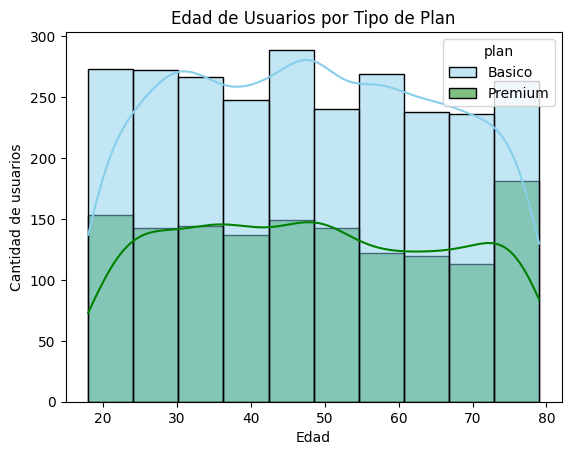

In [30]:
# Histograma para visualizar la edad (age)
sns.histplot(data=user_profile, x='age', hue='plan', bins=10, palette=['skyblue','green'], kde=True)

plt.xlabel('Edad')
plt.ylabel('Cantidad de usuarios')
plt.title('Edad de Usuarios por Tipo de Plan')

plt.show()

<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Histogramas con <code>hue='plan'</code>, la paleta indicada, KDE y título.
</div>

<div class="alert alert-block alert-info">
<b>💡 Comentario del revisor. (Iteración 1) — Tip de eficiencia</b> <a class="tocSkip"></a><br>
Agrega la etiqueta del eje Y (por ejemplo, "Cantidad de usuarios") con <code>plt.ylabel()</code> en los cuatro histogramas.
</div>

💡Insights: 
- Dentro del ambos planes, la edad tiene una distribución aproximadamente uniforme.
  

<div class="alert alert-block alert-warning">
<b>⚠️ Comentario del revisor. (Iteración 1) — Recomendación</b> <a class="tocSkip"></a><br>
Antes de afirmar que el grupo más grande de Premium tiene entre 70 y 80 años, ten en cuenta que con 10 barras y un subconjunto de clientes las diferencias pueden ser ruido. Con todos los clientes, la edad tiene una distribución aproximadamente <b>uniforme</b> en ambos planes. Si quieres comparar los planes, usa proporciones (<code>stat='density', common_norm=False</code>).
</div>

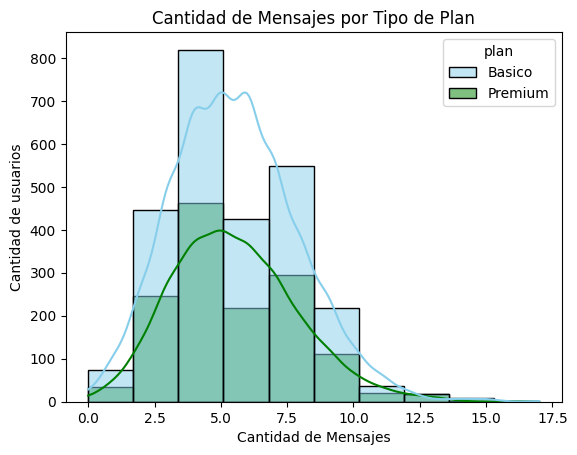

In [31]:
# Histograma para visualizar la cant_mensajes
sns.histplot(data=user_profile, x='cant_mensajes', hue='plan', bins=10, palette=['skyblue','green'], kde=True)

plt.xlabel('Cantidad de Mensajes')
plt.ylabel('Cantidad de usuarios')
plt.title('Cantidad de Mensajes por Tipo de Plan')

plt.show()

💡Insights: 
- La distribución de los datos no es totalmente simétrica, sino que ambos tipos de plan tienen una cola hacia la derecha, con pocos usarios que tienen entre 12 y 17 mensajes, por lo que es ligeramente sesgada a la derecha.

<div class="alert alert-block alert-warning">
<b>⚠️ Comentario del revisor. (Iteración 1) — Recomendación</b> <a class="tocSkip"></a><br>
Revisa la forma: la distribución de mensajes tiene una cola hacia la derecha (pocos usuarios con 12 a 17 mensajes), así que es ligeramente <b>sesgada a la derecha</b>, no simétrica. Muy bien la comparación entre planes.
</div>

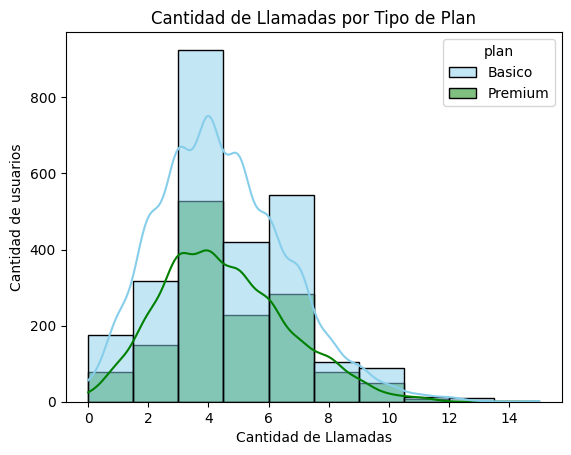

In [32]:
# Histograma para visualizar la cant_llamadas
sns.histplot(data=user_profile, x='cant_llamadas', hue='plan', bins=10, palette=['skyblue','green'], kde=True)

plt.xlabel('Cantidad de Llamadas')
plt.ylabel('Cantidad de usuarios')
plt.title('Cantidad de Llamadas por Tipo de Plan')

plt.show()

💡Insights: 
- La distribución de los datos esta ligeramente sesgada a la derecha, con pocos usuarios que realicen entre 11 y 14 llamadas.

<div class="alert alert-block alert-warning">
<b>⚠️ Comentario del revisor. (Iteración 1) — Recomendación</b> <a class="tocSkip"></a><br>
Mismo comentario: la distribución de llamadas también es ligeramente sesgada a la derecha. Bien la comparación entre planes.
</div>

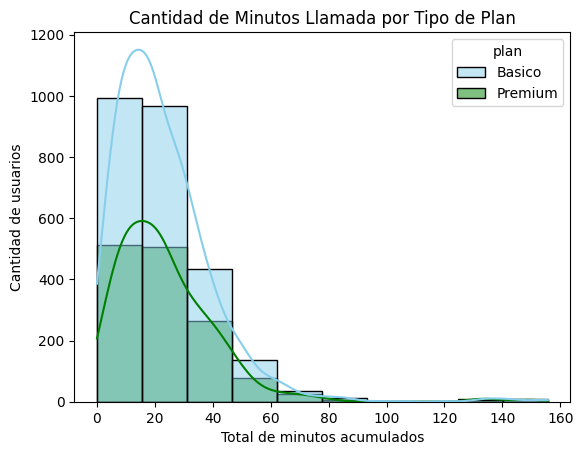

In [33]:
# Histograma para visualizar la cant_minutos_llamada
sns.histplot(data=user_profile, x='cant_minutos_llamada', hue='plan', bins=10, palette=['skyblue','green'], kde=True)

plt.xlabel('Total de minutos acumulados')
plt.ylabel('Cantidad de usuarios')
plt.title('Cantidad de Minutos Llamada por Tipo de Plan')

plt.show()


💡Insights: 
- Los datos no se distribuyen uniformemente, sino que hay una larga cola a la derecha, es decire, los datos estan sesgados a la derecha. La mayoria de los usuarios acumula entre 1 y 30 minutos en total y hay unos pocos entre 80 y 150.

<div class="alert alert-block alert-warning">
<b>⚠️ Comentario del revisor. (Iteración 1) — Recomendación</b> <a class="tocSkip"></a><br>
Bien identificado el sesgo a la derecha. Precisión: <code>cant_minutos_llamada</code> es el <b>total de minutos acumulados por usuario</b> en el periodo, no la duración de cada llamada. La lectura correcta sería "la mayoría de los usuarios acumula entre 1 y 30 minutos en total". Ajusta también la etiqueta del eje X.
</div>

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>
- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
- Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

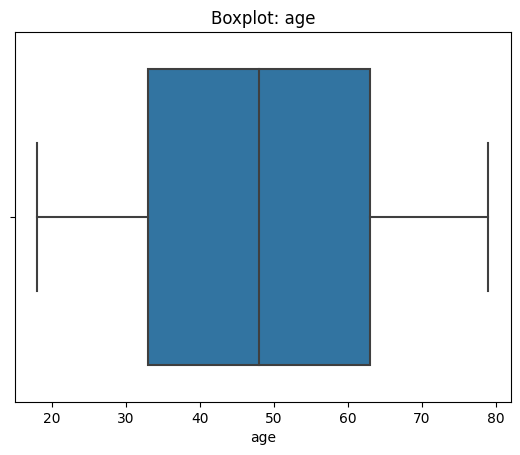

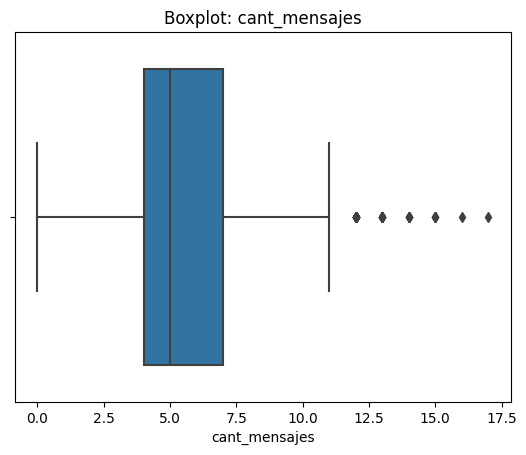

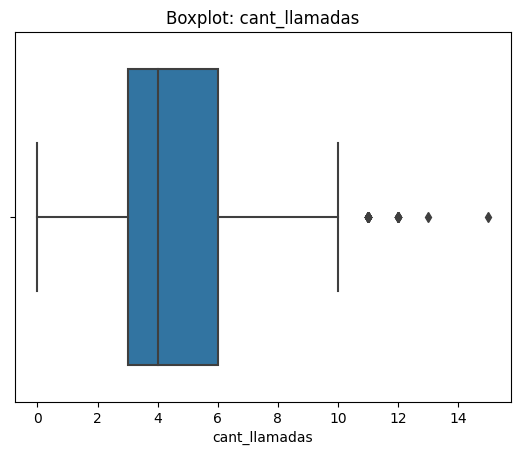

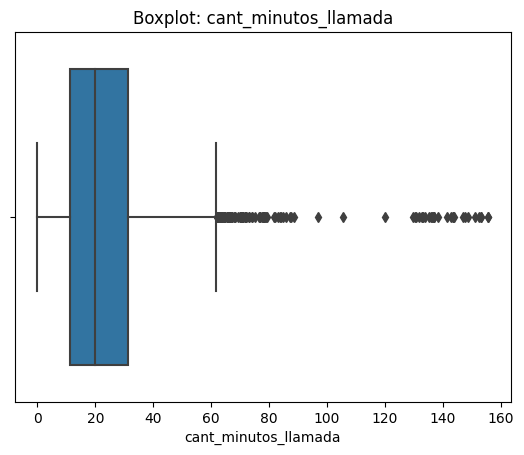

In [34]:
# Visualizando usando BoxPlot 
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas:
    sns.boxplot(x=user_profile[col])
    plt.title(f'Boxplot: {col}')
    plt.show()

<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Boxplots generados con un ciclo <code>for</code> y título dinámico, tal como se pedía.
</div>

💡Insights: 
- Age: no presenta outliers
- cant_mensajes: presenta outliers solo a la derecha, a partir de 12.
- cant_llamadas: presenta outliers solo a la derecha, a partir de 11.
- cant_minutos_llamada: presenta outliers solo a la derecha a partir de 61.

<div class="alert alert-block alert-warning">
<b>⚠️ Comentario del revisor. (Iteración 1) — Recomendación</b> <a class="tocSkip"></a><br>
Las conclusiones son correctas, pero muy breves. Indica de qué lado aparecen los outliers (solo a la derecha) y desde qué valor (por ejemplo, minutos a partir de ~62). Borra también el paréntesis suelto.
</div>

In [35]:
# Calcular límites con el método IQR
columnas_limites = ['cant_mensajes','cant_llamadas','cant_minutos_llamada']

for col in columnas_limites:
    Q1 = user_profile[col].quantile(0.25)
    print('\nPrimer cuartil: ', Q1)

    Q3 = user_profile[col].quantile(0.75)
    print('Tercer cuartil: ', Q3)
    
    IQR = Q3-Q1
    print('IQR: ', IQR)
    
    upper = Q3 + 1.5 * IQR
    print('Límite superior: ', upper)
    print('Usuarios por encima:', (user_profile[col] > upper).sum())
    print()



Primer cuartil:  4.0
Tercer cuartil:  7.0
IQR:  3.0
Límite superior:  11.5
Usuarios por encima: 46


Primer cuartil:  3.0
Tercer cuartil:  6.0
IQR:  3.0
Límite superior:  10.5
Usuarios por encima: 30


Primer cuartil:  11.1075
Tercer cuartil:  31.4125
IQR:  20.305
Límite superior:  61.870000000000005
Usuarios por encima: 109



<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Cálculo IQR correcto, y acertaste al calcular solo el límite superior, porque no hay outliers del lado inferior.
</div>

<div class="alert alert-block alert-info">
<b>💡 Comentario del revisor. (Iteración 1) — Tip de eficiencia</b> <a class="tocSkip"></a><br>
Agrega cuántos usuarios superan el límite para dimensionar el grupo de outliers:<br><code>print('Usuarios por encima:', (user_profile[col] &gt; upper).sum())</code>
</div>

In [36]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,4000.000000,4000.000000
mean,5.523000,4.477000,23.311225
std,2.359738,2.145139,18.169564
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.107500
50%,5.000000,4.000000,19.780000
75%,7.000000,6.000000,31.412500
max,17.000000,15.000000,155.690000


💡Insights: 
- cant_mensajes: mantener los outliers, porque a pesar de no ser tan cercanos a la media siguen estando en el límite de mensajes que ambos planes dan como parte de su servicio.
- cant_llamadas: mantener los outliers, porquea pesar de no ser tan cercanos a la media tampoco son valores extremadamente lejanos de los datos centrales.
- cant_minutos_llamada: mantener los outliers, porque a pesar de estar lejos de la media sigue estando dentro del límite de minutos incluidos en el servicio Premium.

<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Decisión correcta: conservar los outliers porque son valores posibles, y muy buena idea compararlos con lo que incluyen los planes.
</div>

<div class="alert alert-block alert-info">
<b>💡 Comentario del revisor. (Iteración 1) — Tip de eficiencia</b> <a class="tocSkip"></a><br>
Ten en cuenta que los totales por usuario son del periodo completo, mientras que los planes incluyen mensajes y minutos <b>por mes</b>. Esa diferencia hace que el consumo real quede aún más por debajo de lo incluido.
</div>

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [37]:
# Crear columna grupo_uso

import numpy as np

user_profile['grupo_uso'] = np.where((user_profile['cant_llamadas'] < 5) & (user_profile['cant_mensajes'] < 5),'Bajo uso', np.where((user_profile['cant_llamadas'] < 10) & (user_profile['cant_mensajes'] < 10),'Uso medio','Alto uso'))



<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Segmentación con <code>np.where</code> anidados, como sugiere la rúbrica, con las condiciones en el orden correcto.
</div>

<div class="alert alert-block alert-info">
<b>💡 Comentario del revisor. (Iteración 1) — Tip de eficiencia</b> <a class="tocSkip"></a><br>
El aviso <code>SettingWithCopyWarning</code> aparece porque <code>user_profile_2024</code> es un filtro de otro DataFrame. Al trabajar con el <code>user_profile</code> completo desaparece. Si alguna vez necesitas filtrar y luego modificar, usa <code>.copy()</code> al crear el subconjunto.
</div>

In [38]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00,Basico,0,7.0,3.0,23.70,Uso medio
1,10001,Mateo,Torres,53.0,0,2022-01-01 06:34:17.914478619,Basico,0,5.0,10.0,33.18,Alto uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,0,5.0,2.0,10.74,Uso medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,0,11.0,3.0,8.99,Alto uso
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,0,4.0,3.0,8.01,Bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [39]:
# Crear columna grupo_edad
user_profile['grupo_edad'] = np.where((user_profile['age']< 30),'Joven', np.where((user_profile['age']< 60),'Adulto','Adulto Mayor'))

<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Segmentación por edad correcta, con los cortes pedidos.
</div>

In [40]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00,Basico,0,7.0,3.0,23.70,Uso medio,Adulto
1,10001,Mateo,Torres,53.0,0,2022-01-01 06:34:17.914478619,Basico,0,5.0,10.0,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,0,5.0,2.0,10.74,Uso medio,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,0,11.0,3.0,8.99,Alto uso,Adulto Mayor
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,0,4.0,3.0,8.01,Bajo uso,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

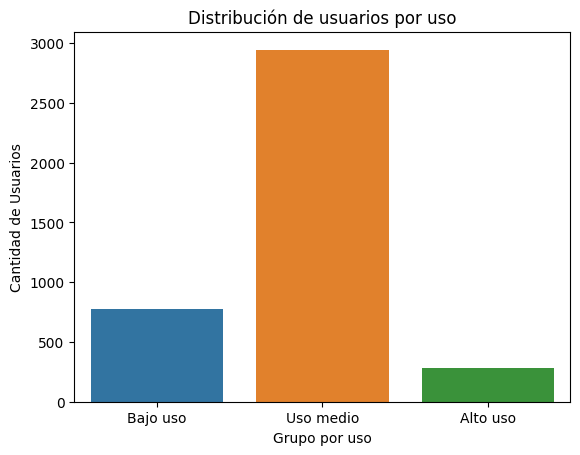

Uso medio    73.58
Bajo uso     19.48
Alto uso      6.95
Name: grupo_uso, dtype: float64


In [41]:
# Visualización de los segmentos por uso

porcentajes_usuarios_por_uso = user_profile['grupo_uso'].value_counts(normalize=True).mul(100).round(2)
sns.countplot(data=user_profile, x='grupo_uso', order=['Bajo uso','Uso medio','Alto uso'])


plt.title('Distribución de usuarios por uso')
plt.xlabel('Grupo por uso')
plt.ylabel('Cantidad de Usuarios')


plt.show()
print(porcentajes_usuarios_por_uso)

<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Countplot con título y etiquetas en ambos ejes.
</div>

<div class="alert alert-block alert-info">
<b>💡 Comentario del revisor. (Iteración 1) — Tip de eficiencia</b> <a class="tocSkip"></a><br>
Ordena las categorías de forma lógica con <code>order=['Bajo uso','Uso medio','Alto uso']</code>, y muestra sus porcentajes con <code>value_counts(normalize=True)</code> para usarlos en el resumen ejecutivo.
</div>

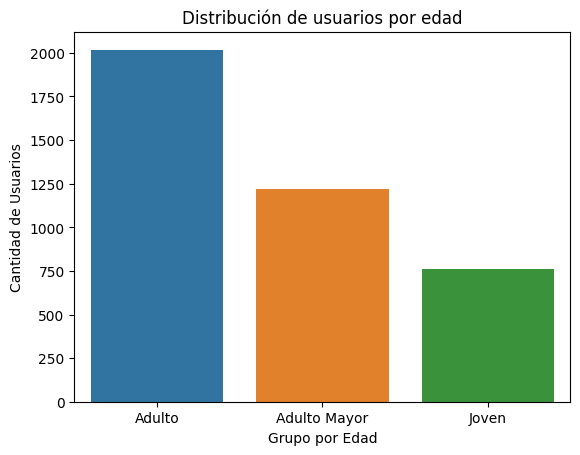

Adulto          50.45
Adulto Mayor    30.55
Joven           19.00
Name: grupo_edad, dtype: float64


In [42]:
# Visualización de los segmentos por edad
porcentajes_usuarios_por_edad = user_profile['grupo_edad'].value_counts(normalize=True).mul(100).round(2)
sns.countplot(data=user_profile, x='grupo_edad')

plt.title('Distribución de usuarios por edad')
plt.xlabel('Grupo por Edad')
plt.ylabel('Cantidad de Usuarios')

plt.show()
print(porcentajes_usuarios_por_edad)

<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Gráfico de edad bien rotulado. Ambos countplots cumplen lo pedido.
</div>


---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

✍️ **Escribe aquí tu análisis ejecutivo:**

### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**
- En el dataset nombrado con la variable users, había 469 datos nulos en la columna 'city' y 3534 datos nulos en la columna 'churn_date', lo cual representaba un  11.73% y un 88.35% de valores nulos de sus repectivas columnas.
- En el dataset nombrado con la variable usage, había 50 datos nulos en la columna 'date', 22076 en la columna 'duration' y 17896 en la columna 'length', lo cual representaba un 0.13%, 55.19% y un 44.74% de valores nulos de sus repectivas columnas.
- Se identificaron los siguientes sentinels: 55 edades con -999 y 96 '?' en city.
- Se identificaron 40 fechas en el año 2026, año del cual no hay registros.


🔍 **Segmentos por Edad**
- Se identificaron tres segmentos de clientes por edad: 19% Joven, 50.45% Adulto y 30.55% Adulto mayor. 
- El comportamiento de estos datos muestra que la mayor cantidad de clientes pertenece al grupo 'Adulto', en el cual se encuentran aquellas personas que tienen entre 30 y 60 años, el segundo grupo con mayor proporción de clientes es el de 'Adulto Mayor' en el cual se encuentran las personas mayores de 60 años, y por último, el segmento con menor proporción de clientes es el 'Joven' donde se encuntran aquellas personas menores de 30 años.


📊 **Segmentos por Nivel de Uso**
- Se identificiaron tres segmentos de clientes por uso: 19.48% Bajo uso, 73.58% Uso Medio y 6.95% Alto uso.
- El comportamiento de estos datos muestra que la mayor proporción de clientes le da un uso medio a su servicio, mientras que una menor proporción le da un bajo uso y solo una mínima proporción le da un alto uso.


➡️ Esto sugiere que a pesar de que los patrones de uso extremo (outliers) encontrados representan un comportamiento real de los datos, solo son una mínima proporción de clientes, por lo que el servicio no se debe enfocar en ellos, sino en el mayor segmento de clientes que se encuentran dentro de la distribución central de los datos y que son los que le dan un uso medio al servicio y tienen una edad de entre 30 y 60 años.

Ambos tipos de clientes, los de plan Básico y los de plan Premium usan el servicio de manera similar y realizan casi la misma cantidad de llamadas y envíos de mensajes.


💡 **Recomendaciones**
- Podría crearse un tipo de plan intermedio, entre el el plan Básico y el plan Premium, el cual incluya una mayor cantidad de mensajes y llamadas que el plan Básico, pero una menor que el plan Premium y tenga un precio intermedio entre ambos planes.
- Podrían realizarse promociones para atraer clientes que aún esten en el plan básico, pero que tengan un alto uso del servicio, brindando llamadas y mensajes a un precio mas bajo durante un periodo determinado.



<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Buen enfoque: identificas los segmentos y concluyes que el grupo central (uso medio y adultos) es el más relevante. La propuesta de un plan intermedio es concreta y está conectada con el análisis.
</div>

<div class="alert alert-block alert-warning">
<b>⚠️ Comentario del revisor. (Iteración 1) — Recomendación</b> <a class="tocSkip"></a><br>
Para completarlo:
<ul>
<li><b>Problemas:</b> además de los nulos, agrega los sentinels (55 edades con <code>-999</code> y 96 <code>"?"</code> en <code>city</code>) y las 40 fechas de 2026.</li>
<li><b>Segmentos:</b> indica el tamaño de cada uno con cifras. Después de trabajar con todos los clientes, con <code>value_counts(normalize=True)</code> los obtienes directamente.</li>
<li><b>Comportamiento:</b> ¿cómo consume cada segmento? ¿Básico y Premium usan el servicio de forma distinta?</li>
<li><b>Recomendaciones:</b> amplía con más propuestas (por ejemplo, qué hacer con los clientes de bajo uso o con los de alto uso).</li>
</ul>
</div>

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnetaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`

<div class="alert alert-block alert-warning">
<b>⚠️ Comentario del revisor. (Iteración 1) — Recomendación</b> <a class="tocSkip"></a><br>
Escribe el link en esta celda Markdown, reemplazando el texto de la plantilla <code>`LINK a tu repo aquí`</code>.
</div>

In [ ]:
https://github.com/jzamorano11/sprint7-final-project

<div class="alert alert-block alert-warning">
<b>⚠️ Comentario del revisor. (Iteración 1) — Recomendación</b> <a class="tocSkip"></a><br>
El link quedó en una celda de <b>código</b>: al ejecutar todo el notebook, esta celda produce un <code>SyntaxError</code>. Muévelo a la celda Markdown de arriba y elimina esta celda. Asegúrate también de que el repositorio tenga el notebook y un <code>README.md</code> con objetivo, datasets, etapas del análisis y cómo ejecutarlo.
</div>

<div class="alert alert-block alert-info">
<b>💡 Comentario del revisor. (Iteración 1) — Tip de eficiencia</b> <a class="tocSkip"></a><br>
<b>📊 Evaluación según la rúbrica DA Sprint 7</b><br><table><tr><th>Parte</th><th>Criterio</th><th>Estado</th></tr><tr><td>1. Carga y exploración</td><td>Librerías, carga, head/info/shape</td><td>✅</td></tr><tr><td>2. Calidad de datos</td><td>Nulos (conteo y proporción)</td><td>✅</td></tr><tr><td></td><td>Sentinels (-999 y "?")</td><td>✅</td></tr><tr><td></td><td>Fechas (errors='coerce', .dt.year)</td><td>✅</td></tr><tr><td></td><td>Diagnóstico escrito</td><td>🟡 acciones a ajustar</td></tr><tr><td>3. Limpieza</td><td>Mediana en age + validación</td><td>✅ (sugerencia: excluir sentinel)</td></tr><tr><td></td><td>"?" → pd.NA</td><td>✅</td></tr><tr><td></td><td>Fechas imposibles → nulo</td><td>🟡 reg_date quedó como año</td></tr><tr><td></td><td>Evaluación MAR y decisión</td><td>✅</td></tr><tr><td>4. Uso por usuario</td><td>Agrupación, métricas y merge</td><td>✅</td></tr><tr><td></td><td>Revisión estadística</td><td>❌ solo clientes registrados en 2024 (1330 de 4000)</td></tr><tr><td>5. Distribuciones y outliers</td><td>Histogramas con hue</td><td>✅</td></tr><tr><td></td><td>Interpretación</td><td>🟡 forma y minutos a precisar</td></tr><tr><td></td><td>Boxplots e IQR</td><td>✅</td></tr><tr><td>6. Segmentación</td><td>grupo_uso / grupo_edad</td><td>✅</td></tr><tr><td></td><td>Countplots rotulados</td><td>✅</td></tr><tr><td>7. Insight ejecutivo</td><td>Segmentos y recomendaciones</td><td>✅</td></tr><tr><td></td><td>Cifras y problemas</td><td>🟡 faltan sentinels, 2026 y tamaños</td></tr><tr><td>8. Publicación</td><td>Link al repositorio</td><td>🟡 en celda de código</td></tr></table><br>Un criterio en ❌ → <b>proyecto devuelto para una nueva iteración</b>.
</div>

<div class="alert alert-block alert-info">
<b>Comentario del revisor. (Iteración 1) — Próximos pasos</b> <a class="tocSkip"></a><br><br>
Tu proyecto tiene una base sólida y está a un paso de la aprobación. Para la siguiente iteración, el único punto bloqueante ❌ es:
<ol><li><b>Paso 4.2 en adelante:</b> trabajar con el <code>user_profile</code> completo (4000 clientes) en lugar del filtro por año de registro, y volver a ejecutar los gráficos, el IQR y la segmentación.</li></ol>
En la siguiente iteración revisaré únicamente este punto, así que no habrá requisitos nuevos. Las recomendaciones 🟡 son opcionales, aunque te sugiero especialmente conservar la fecha completa en <code>reg_date</code>, completar el resumen ejecutivo con cifras y mover el link a la celda Markdown.<br><br>
¡Ánimo, ya casi está! 💪
</div>